# Programmation Python  pour les mathématiques

**Julien Guillod**, [Sorbonne Université](http://www.sorbonne-universite.fr/),
Licence <a href="https://creativecommons.org/licenses/by-nc-nd/4.0/">CC BY-NC-ND</a>

L'entier des chapitres est disponible au format
[HTML](https://python.guillod.org/) et [PDF](https://python.guillod.org/python.pdf).
Ce notebook peut également être exécuté sur [GESIS](https://notebooks.gesis.org/binder/v2/gh/guillod/python/master?urlpath=lab/tree/chap04.ipynb).

# 4 Calcul symbolique

<div id="ch:sympy"></div>

En tant que langage généraliste, Python n'inclut pas par défaut certains concepts mathématiques. Un exemple déjà vu concerne les vecteurs et les matrices numériques qui sont implémentée dans le module Numpy. Le but ici est d'introduire le module Sympy qui permet de faire du calcul symbolique.

**Concepts abordés:**

* symboles

* fonctions

* simplification

* analyse infinitésimale (limite, dérivation, intégration, développement limité)

* preuve assistée par ordinateur

* fonction pathologique

* fonction de Green

* coordonnées sphériques

Par exemple, le nombre $\sqrt{8}$ est représenté par Python comme un flottant:

In [1]:
import math
math.sqrt(8)

2.8284271247461903

L'avantage de Sympy est que $\sqrt{8}$ est gardé en tant racine et même automatiquement simplifié:

In [2]:
import sympy as sp
sp.init_printing()
sp.sqrt(8)

À noter que la deuxième instruction n'est pas nécessaire, mais permet de présenter les résultats de manière plus élégante dans Jupyter Lab.
Même si cela est déconseillé, il est possible d'importer toutes les fonctions de Sympy afin de ne pas avoir à mettre `sp.` devant chaque fonction:

```Python
        from sympy import *
        init_printing()
        sqrt(8)
```

mais il faut alors faire attention aux éventuels conflits entre fonctions.
En particulier si Numpy ou le module `math` sont utilisés également alors il ne faut pas utiliser `import *`. La documentation de Sympy est disponible [ici](https://docs.sympy.org/).

# Exercice 4.1: Introduction à Sympy

Avant de pouvoir utiliser des variables symboliques, il faut les déclarer comme symboles:

In [3]:
x = sp.Symbol("x") # définit le symbole x
y = sp.Symbol("y", real=True) # définit la variable réelle y
e = sp.Symbol(r"\varepsilon", real=True, positive=True) # définit epsilon positif

Ensuite il est possible de faire des opérations entre symboles:

In [4]:
x + 2*y + e/4 + x**2 + 3*x + 2*y

La plupart des fonctions mathématiques sont implémentées symboliquement dans Sympy et il est également possible de les simplifier:

In [5]:
expr = sp.cos(x)**2 + sp.sin(x)**2 + (y**3 + y**2 - y - 1)/(y**2 + 2*y + 1) + sp.exp(-e)
sp.simplify(expr)

Finalement il est possible de faire des substitutions:

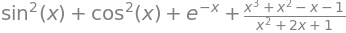

In [6]:
expr.subs(x,y) # remplace x par y
expr.subs({y:x, e:y}) # remplace y par x et e par y

puis par exemple de simplifier l'expression et de tracer son graphe en fonction de `x` comme sur la [fig:sympy-plot](#fig:sympy-plot):

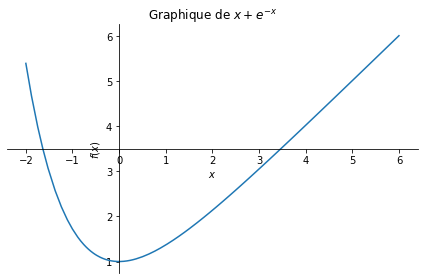

In [7]:
f = sp.simplify(expr.subs({y:x, e:y}))
sp.plot(f,(x,-2,6), title=f"Graphique de ${sp.latex(f)}$")

<div id="fig:sympy-plot"></div>
<p>Représentation graphique d'une fonction Sympy.</p><center><img src="https://python.guillod.org/fig/sympy-plot.png" style="width:90%;max-width:700px;"></center>

**a)**
Lire la documentation de la fonction `solve` et l'utiliser pour calculer les racines d'un polynôme général de degré deux, puis de degré trois.

**Indication:**
La documentation sur la résolution d'équations algébriques est disponible [ici](https://docs.sympy.org/latest/modules/solvers/solvers.html#algebraic-equations).

In [8]:
# Polynome de degré 2
a = sp.Symbol("a")
b = sp.Symbol("b")
c = sp.Symbol("c")
eq = a*x**2 + b*x + c

sp.solve(eq,x)

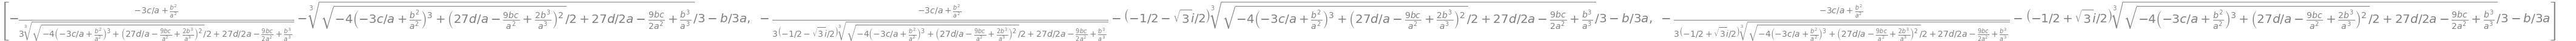

In [9]:
# Polynome de degré 3
a = sp.Symbol("a")
b = sp.Symbol("b")
c = sp.Symbol("c")
d = sp.Symbol("d")

eq = a*x**3 + b*x**2 + c*x  + d

sp.solve(eq,x)

**b)**
Lire la documentation des fonctions `evalf` et `N` pour évaluer l'expression $\frac{\pi^2}{4}$.

**Indication:**
La documentation sur l'évaluation numérique est disponible [ici](https://docs.sympy.org/latest/modules/evalf.html).

In [10]:
print('via la méthode N : ', sp.N(sp.pi**2 / 4))
print('via la méthode evalf : ',(sp.pi**2 / 4).evalf())

# On confirme que les deux évaluations sont égales :
(sp.pi**2 / 4).evalf() == sp.N(sp.pi**2 / 4)

via la méthode N :  2.46740110027234
via la méthode evalf :  2.46740110027234


True

**c)**
Déterminer la partie réelle et imaginaire de l'expression:

$$
\bigg(\frac{1+i\sqrt{3}}{1+i}\bigg)^{20} \,.
$$

**Indication:**
Voir la documentation [ici](https://docs.sympy.org/latest/modules/functions/elementary.html).

In [11]:
expr = ((1 + sp.I*sp.sqrt(3))/(1+sp.I))**20
r = sp.re(expr)
i = sp.im(expr)

print('les parties réelles et imaginaires sont')
r,i

les parties réelles et imaginaires sont


**d)**
Lire la documentation de la fonction `diff` et calculer la dérivée de $x e^{x^{x^x}}$ par rapport à $x$.

**Indication:**
La documentation sur les dérivées est disponible [ici](https://docs.sympy.org/latest/tutorial/calculus.html#derivatives).

In [12]:
e = sp.exp(1)
expr = x*e**x**x**x
sp.diff(expr,x)

**e)**
Lire la documentation de la fonction `integrate` et calculer les intégrales suivantes:

$$
\begin{align*}
I_{1} & =\int x^{5}\sin(x)\,\mathrm{d} x \,, &  I_{2} & =\int_{0}^{\infty}\sin(x^{2})\,\mathrm{d} x \,.
\end{align*}
$$

In [13]:
f_1 = x**5*sp.sin(x)
sp.integrate(f_1,x)

In [14]:
f_2 = sp.sin(x**2)
sp.integrate(f_2,(x,0,sp.oo))

**f)**
Calculer avec Sympy les limites suivantes:

$$
\begin{align*}
L_{1} & =\lim_{x\to0}\frac{\sin(x)}{x}\,, & L_{2} & =\lim_{x\to0}\sin\bigg(\frac{1}{x}\bigg)\,, & L_{3} & =\lim_{x\to\infty}\frac{5x^{2}+3x+2y}{y(x-4)(x-y)}\,.
\end{align*}
$$

In [15]:
eq_1 = sp.sin(x)/x
sp.limit(eq_1,x,0)

In [16]:
eq_2 = sp.sin(1/x)
sp.limit(eq_2,x,0)

In [17]:
eq_3 = (5*x**2 + 2*y)/(y*(x-4)*(x-y))
sp.limit(eq_3,x,sp.oo)

**g)**
Calculer le développement limité de $\tan(x)$ en $x=0$ à l'ordre 10 et le développement asymptotique de $\left(1 + \frac{1}{n}\right)^n$ pour $n\to\infty$ à l'ordre 5.

In [18]:
eq = sp.tan(x)
eq.series(x,0,10)

In [19]:
n = sp.Symbol('n')
eq = (1+1/n)**n

eq.series(n,sp.oo,5)

**h)**
Déterminer les valeurs propres de la matrice:

$$
\begin{pmatrix}1 & a & 0\\ 
a & 2 & a\\ 
0 & a & 3
\end{pmatrix}
$$

In [20]:
import sympy as sp

a = sp.Symbol('a')
m = sp.Matrix([[1, a, 0], [a, 2, a], [0, a, 3]])
m.eigenvals()

**Indication:**
La documentation sur les matrices symboliques est disponible [ici](https://docs.sympy.org/latest/tutorial/matrices.html).

# Exercice 4.2: Applications

Le but est d'utiliser Sympy pour résoudre symboliquement différents problèmes mathématiques en calculant le moins de choses possibles à la main.

**a)**
Déterminer le nombre de zéros que contient l'entier $123!$.

In [21]:
str(sp.factorial(123)).count('0')

**b)**
Déterminer le rapport entre la hauteur et le rayon d'un cylindre de manière à minimiser son aire à volume fixé.

In [22]:
r = sp.Symbol('r',real=True,positive=True) # Rayon
h = sp.Symbol('h',real=True,positive=True) # Hauteur
volume = sp.pi*r**2*h
surface = 2*sp.pi*r**2 +  2*sp.pi*r*h

In [23]:
v = sp.Symbol('v',real=True,positive=True) # volume
h_0 = sp.solve(volume-v,h) # h pour un volume donné
S = surface.subs(h,h_0[0])  # on remplace h par la solution de l'equation de surface

In [24]:
r_0 = sp.solve(sp.diff(S,r),r)[0]
eq = r_0.subs(v,volume)-r
sp.solve(eq,r)

**c)**
Pour $x,y\in\mathbb{R}$ tels que $xy < 1$, démontrer que:

$$
\arctan(x) + \arctan(y) = \arctan\left(\frac{x+y}{1-xy}\right) \,.
$$

**Indication:**
Dériver l'équation par rapport à $x$ et justifier.

In [25]:
# On définit une fonction f comme la différence des deux membres de l'équation proposée
# On tente de démontrer que cette fonction est constante, via l'étude de sa fonction dérivée.

x = sp.Symbol('x',real=True)
y = sp.Symbol('y',real=True)
f = sp.atan(x) + sp.atan(y) - sp.atan((x+y)/(1-x*y))

sp.simplify(sp.diff(f,x))
# La dérivée étant la fonction nulle on déduit que f est constante, et donc que l'égalité est respectée.

**d)**
Démontrer la formule suivante due à Gauss:

$$
\frac{\pi}{4} = 12\arctan\left(\frac{1}{38}\right)+20\arctan\left(\frac{1}{57}\right)+7\arctan\left(\frac{1}{239}\right)+24\arctan\left(\frac{1}{268}\right) \,.
$$

Il est impératif d'utiliser Sympy, la démonstration originale de Gauss faisant 25 pages, voir les pages 477 à 502 du deuxième volume de ses œuvres complètes disponible [ici](https://gallica.bnf.fr/ark:/12148/bpt6k99402s).

**Indication:**
Appliquer la fonction tangente de chaque côté de l'équation puis simplifier. La documentation sur les différentes fonctions de simplifications est disponible [ici](https://docs.sympy.org/latest/tutorial/simplification.html).

In [26]:
x = 12*sp.atan(sp.Rational(1,38))+20*sp.atan(sp.Rational(1,57)) + 7*sp.atan(sp.Rational(1,239))+24*sp.atan(sp.Rational(1,268))
sp.expand_trig(sp.tan(x))

In [27]:
sp.tan(sp.pi/4)

**e)**
Déterminer le volume de la région:

$$
\big\{(x,y,z)\in\mathbb{R}^3: x^2+y^2 < z < 2x^2+4xy+6y^2, |y| < 5, |x| < 4\big\} \,.
$$

In [28]:
x,y,z = sp.symbols("x y z")
sp.integrate(1,(z,x**2+y**2,2*x**2+6*y**2),(y,-5,5),(x,-4,4))

**f)**
Déterminer l'expression des coefficients de Fourier réels de la fonction $2\pi$-périodique $f$ définie par $f(x)=|\sin(x)|$.

In [29]:
x = sp.Symbol("x",real=True)
n = sp.Symbol("n", integer=True,positive=True)
f = abs(sp.sin(x))

a0 = sp.integrate(f,(x,0,2*sp.pi))/(2*sp.pi)
an = sp.integrate(f*sp.cos(n*x),(x,0,2*sp.pi))/(2*sp.pi)
bn = sp.integrate(f*sp.sin(n*x),(x,0,2*sp.pi))/(2*sp.pi)

sp.simplify((a0,an,bn))

⎛   ⎧  ⎛    n + 1    ⎞              ⎞
⎜   ⎪2⋅⎝(-1)      - 1⎠              ⎟
⎜   ⎪─────────────────  for n ≠ 1   ⎟
⎜   ⎨       2                       ⎟
⎜   ⎪      n  - 1                   ⎟
⎜   ⎪                               ⎟
⎜2  ⎩        0          otherwise   ⎟
⎜─, ─────────────────────────────, 0⎟
⎝π               2⋅π                ⎠

# Exercice 4.3: Fonction pathologique

Le but est de construire une fonction qui visuellement semble régulière, mais qui en fait ne l'est pas.
Soit la fonction $f:\mathbb{R}\to\mathbb{R}$ définie par:

$$
f(x) = \sum_{k=1}^{\infty} \frac{\sin(k^2 x)}{k^5} \,.
$$

Vu que la série converge absolument, la fonction $f$ est bien définie.

**a)**
À l'aide de Sympy calculer la fonction $g:\mathbb{R}\to\mathbb{R}$ définie en gardant les cent premiers termes de la série:

$$
g(x) = \sum_{k=1}^{100} \frac{\sin(k^2 x)}{k^5} \,,
$$

In [30]:
x,k = sp.symbols("x k")
g = sp.summation(sp.sin(k**2*x)/k**5,(k,1,100))

et représenter la fonction $g$ graphiquement.

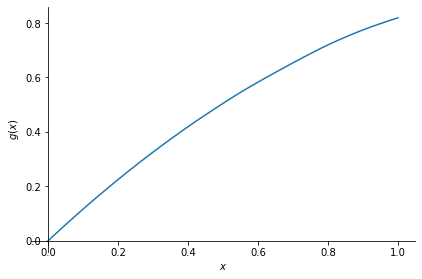

In [31]:
sp.plot(g,(x,0,1),ylabel=r'$g(x)$')

**b)**
Estimer à la main l'erreur entre les fonctions $f$ et $g$ en valeur absolue.

En utilisant l'inégalité triangulaire puis le fait que pour tout x réel, |sin(x)| ≤ 1 on aboutit à <br>

$|g(x) - f(x)| ≤  \int_{101}^{\infty}\frac{1} {k^5} dk  ≤ 2.5*10^{-9} $

**c)**
Calculer la dérivée première et la dérivée seconde de $g$ et représenter graphiquement ces deux dérivées. Que pouvez-vous conclure ?

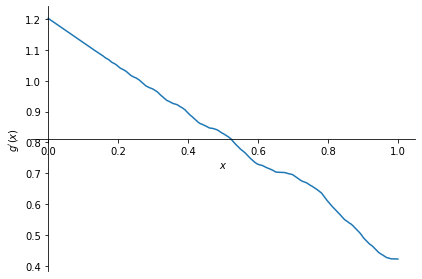

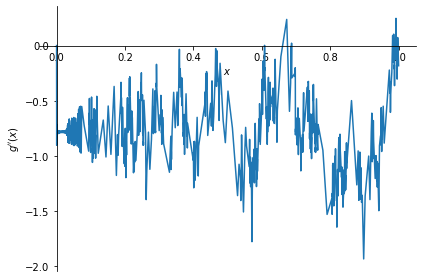

In [32]:
g_prime = sp.diff(g,x)
g_second = sp.diff(g_prime,x)

sp.plot(g_prime,(x,0,1),ylabel=r"$g^{\prime}(x)$")
sp.plot(g_second,(x,0,1),ylabel=r"$g^{\prime\prime}(x)$")

**d)**
Expliquer mathématiquement ce qui se passe.

En dérivant la série entière f à 2 reprises on s'aperçoit que f" n'est pas convergente pour tout x, et donc que f' n'est pas dérivable. On conclut f est de classe C_0 et non de classe C_1

# Exercice 4.4: <span style="color:red">!</span> Fonction de Green du laplacien

Le but de cet exercice est de calculer entièrement automatiquement la fonction de Green du laplacien dans $\mathbb{R}^3$, *i.e.* la solution satisfaisant:

$$
\Delta G(\boldsymbol{x}) = \delta(\boldsymbol{x}) \,,
$$

dans $\mathbb{R}^3$ où $\delta(\boldsymbol{x})$ est la distribution de Dirac.

Pour cela, nous introduisons les coordonnées sphériques $\boldsymbol{x}^\prime = (r,\theta,\varphi)$ avec $r>0$, $0 \leq \theta \leq \pi$, et $0 \leq \varphi < 2\pi$ caractérisées par:

$$
\begin{align*}
x_1 & =r\cos\varphi\sin\theta\\ 
x_2 & =r\sin\varphi\sin\theta\\ 
x_3 & =r\cos\theta \,.
\end{align*}
$$

**a)**
Définir une fonction `to_spherical(expr)` permettant de convertir en coordonnées sphériques une expression donnée en coordonnées cartésiennes.

In [33]:
x1,x2,x3,r,p,t=sp.symbols("x1 x2 x3 r p t")
def to_spherical(expr):
    expr=expr.subs({x1:r*sp.cos(p)*sp.sin(t),x2:r*sp.sin(p)*sp.sin(t),x3:r*sp.cos(t)})
    return sp.simplify(expr)

**b)**
Définir une fonction `to_cartesian(expr)` permettant de convertir en coordonnées cartésiennes une expression donnée en coordonnées sphériques.
Par simplicité on pourra traiter uniquement le cas d'une expression `expr` invoquant les variables $r$ et $\theta$ mais pas $\varphi$.

In [34]:

coords={sp.cos(p)*sp.sin(t):x1,r*sp.sin(p)*sp.sin(t):x2,r*sp.cos(t):x3}
def to_cartesian(expr):
    return sp.simplify(expr.subs(coords))
to_cartesian(r*sp.sin(t))

**c)**
Calculer les facteurs d'échelle des coordonnées sphériques:

$$
h_i = \left\Vert \frac{\partial\boldsymbol{x}}{\partial x^\prime_i} \right\Vert.
$$

**d)**
Définir une fonction `gradient(f)` permettant de calculer le gradient d'une fonction $f:\mathbb{R}^3\to\mathbb{R}$ en coordonnées sphériques:

$$
\boldsymbol{\nabla}f = \left( \frac{1}{h_i}\frac{\partial f}{\partial x^\prime_i} \right)_{i=1}^3\,.
$$

**e)**
Faire de même pour définir le laplacien en coordonnées sphériques:

$$
\Delta f = \sum_{i=1}^3 \frac{1}{J} \frac{\partial}{\partial x^\prime_i} \left( \frac{J}{h_i^2} \frac{\partial f}{\partial x^\prime_i} \right) \quad \text{où} \quad J = \prod_{i=1}^3 h_i \,.
$$

**f)**
Trouver les solutions radiales (*i.e.* ne dépendant que de la variable $r$) de l'équation $\Delta G = 0$ dans $\mathbb{R}^3\setminus\{\boldsymbol{0}\}$.

**Indication:**
Regarder la documentation de la fonction `dsolve` pour résoudre une équation différentielle.

**g)**
Déterminer les équations que doivent satisfaire les constantes d'intégration pour que la solution précédente satisfasse en coordonnées cartésiennes:

$$
\lim_{|\boldsymbol{x}|\to\infty} G(\boldsymbol{x}) = 0 \quad \text{et} \quad \Delta G(\boldsymbol{x}) = \delta(\boldsymbol{x}) \,.
$$

**Indication:**
Il faut transformer les deux conditions en coordonnées sphériques.
La première condition s'exprime en coordonnées sphériques par:

$$
\lim_{r\to\infty} G(r) = 0 \,,
$$

et la seconde est équivalente à:

$$
\lim_{r \to 0} \int_{0}^{\pi} \int_{0}^{2\pi} \big( \boldsymbol{\nabla} G(r) \boldsymbol{\cdot} \boldsymbol{e}_r \big) \, J(r,\theta,\varphi) \, \mathrm{d}\varphi \mathrm{d}\theta = 1\,.
$$


**h)**
Résoudre les équations sur les constantes d'intégrations et substituer dans la solution radial de $\Delta G = 0$ pour obtenir l'expression de la fonction de Green du laplacien en coordonnées sphériques. Finalement déterminer la fonction de Green $G$ du laplacien dans $\mathbb{R}^3$ en coordonnées cartésiennes.



**i)**
<span style="color:red">!!</span>
Soit $g:\mathbb{R}^3 \to \mathbb{R}$ une fonction lisse à support compact invariante par rotations selon l'axe vertical. Déterminer le comportement asymptotique à grandes distances de la solution de l'équation:

$$
\Delta f(\boldsymbol{x}) = g(\boldsymbol{x}) \,
$$

jusqu'à l'ordre deux, *i.e.* les termes décroissant comme $|\boldsymbol{x}|^{-1}$ et comme $|\boldsymbol{x}|^{-2}$.

**Indication:**
La solution est donnée par la formule de Green:

$$
f(\boldsymbol{x}) = \int_{\mathbb{R}^3} G(\boldsymbol{x}-\boldsymbol{x}_0) g(\boldsymbol{x}_0) \, \mathrm{d}^3\boldsymbol{x}_0 = \int_{B_R} G(\boldsymbol{x}-\boldsymbol{x}_0) g(\boldsymbol{x}_0) \, \mathrm{d}^3\boldsymbol{x}_0 \,,
$$

où $R$ est choisi de sorte que le support de $g$ soit contenu dans $B_R$.
Pour calculer le développement asymptotique de cette intégrale, la première étape est de convertir $G(\boldsymbol{x}-\boldsymbol{x}_0)$ en coordonnées sphériques pour $\boldsymbol{x}$ et $\boldsymbol{x}_0$. Vu que $g$ est invariante par rotations selon l'axe vertical, alors en coordonnées sphériqued $g$ est indépendante de $\varphi$ et est donnée par $g(r,\theta)$.
La deuxième étape est de transformer l'intégrale en coordonnées sphériques avec une intégrale triple sur $r_0$, $\theta_0$ et $\varphi_0$.
La troisième étape est de calculer le développement asymptotique de l'intégrant lorsque $r\to\infty$, jusqu'à l'ordre deux. Finalement, vu que $r_0$, $\theta_0$ et $\varphi_0$ sont bornés, alors l'intégration commute avec le développement asymptotique et le résultat final est donné par l'intégration individuelle des deux termes du développement asymptotique.